<a href="https://colab.research.google.com/github/okechukwupromise49-art/heart-disease-classification./blob/main/Group14_Hearth_Disease_Prevention_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hearth Disease Prevention


## 1. Installation of Dataset Package

In [2]:
!pip install ucimlrepo

## 1.2 import all library

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    fbeta_score,
    roc_auc_score
)

## 2. Download the DataSet into Colab

### 2.1. Data Acquisition

## Dataset Source
The dataset used for this project was obtained from the UCI Machine Learning Repository, a widely used repository for machine learning datasets. The dataset selected is the Heart Disease dataset (Dataset ID: 45).
The dataset was accessed programmatically using the ucimlrepo Python library.
## Dataset Description
The original dataset contains 303 patient records and 13 predictive features. The features contain information relating to patient characteristics, clinical measurements, and results from medical examinations. These features are used to investigate whether a patient has heart disease.

In [4]:
from ucimlrepo import fetch_ucirepo

heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features
y = heart_disease.data.targets

print("features shape", X.shape)
print("target shape", y.shape)

features shape (303, 13)
target shape (303, 1)


### Context
The purpose of using this dataset is to investigate how machine learning classification models can learn patterns from patient-related features and use those patterns to predict the presence of heart disease.

## 3. Data Exploration

### 3.1. Viewing the data

In [5]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


## 3.2. Data tyes and missing value

In [6]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


The data types were inspected to ensure that the features could be processed correctly by the machine learning models. No inappropriate text or date values were found, so no major data-type conversion was required.

## 3.3. statistical summary

In [7]:
X.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000


## 3.4. Missing values in each column

In [7]:
X.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Missing values were found in the ca and thal columns. Since these columns contained only a small number of missing observations, the affected records were investigated before deciding how to handle them.

## 3.5. Duplication rows

In [8]:
X.duplicated().sum()

np.int64(0)

No duplicate rows were found in the feature dataset. Therefore, no rows were removed because of duplication. Keeping all unique records preserves the available information for model training.

## 3.6. Check the target

In [9]:
y.value_counts()

,count
num,
0,164
1,55
2,36
3,35
4,13


## 4. Data Cleaning

### 4.1 Binary Target

#### Create a new binary target rather than destroying the original y

AI generated

In [10]:
y_binary = (y["num"] > 0).astype(int)

In [11]:
y_binary.value_counts()

,count
num,
0,164
1,139


## 4.2. Handle the missing values

### Check which rows contain the missing values

AI generated

In [12]:
X[X["ca"].isnull() | X["thal"].isnull()]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0


 ca and thal are categorical/encoded clinical variables. Simply replacing their missing values with the mean would not make sense. We could use a more sophisticated imputation method, but with only 6 affected observations, removing those rows is straightforward and easy to justify.

In [13]:
X_clean = X.dropna(subset=["ca", "thal"])

Only 6 of the 303 original records contained missing values in ca or thal. Because these features are relevant to the prediction task and the number of affected records was small, removing the incomplete records was chosen instead of estimating their values. This avoids introducing potentially inaccurate values through imputation while retaining the majority of the dataset.

### Now, let’s evaluate the results.


In [14]:
X_clean.shape

(297, 13)

In [15]:
X_clean.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


## 4.3. Align the target with the cleaned data

In [16]:
y_clean = y_binary.loc[X_clean.index]

In [17]:
print("Features:", X_clean.shape)
print("Target:", y_clean.shape)

y_clean.value_counts()

Features: (297, 13)
Target: (297,)


,count
num,
0,160
1,137


## 4.4. Checking for outliers

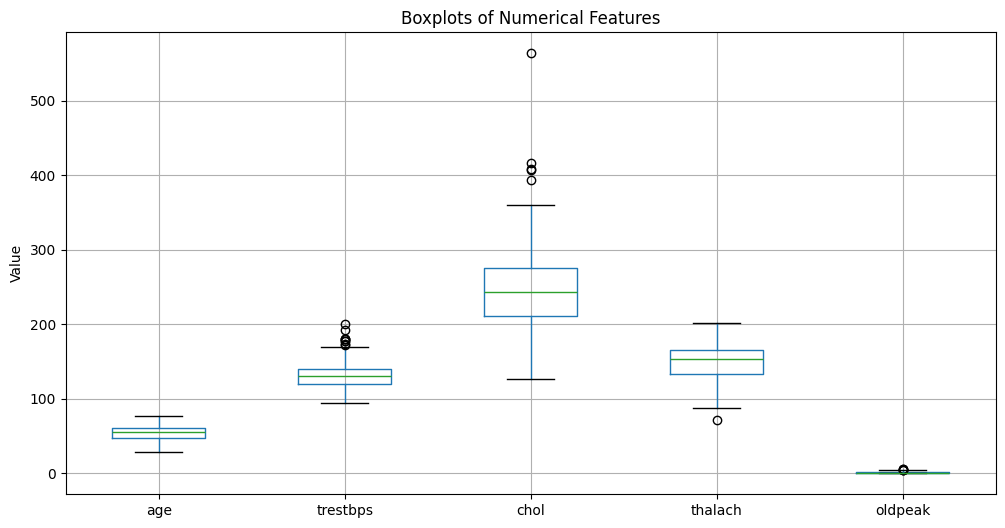

In [18]:
plt.figure(figsize=(12, 6))

X_clean[["age", "trestbps", "chol", "thalach", "oldpeak"]].boxplot()

plt.title("Boxplots of Numerical Features")
plt.ylabel("Value")
plt.xticks(rotation=0)
plt.show()

Boxplots were used to identify potentially unusual values in the numerical features. Some extreme observations were visible, but they were not automatically removed because unusual clinical measurements can represent genuine patient characteristics rather than data-entry errors. Removing them without sufficient evidence could reduce the variability of the dataset and potentially remove useful information. Therefore, the observations were retained for modelling.

## 4.5. Final cleaning check

In [19]:
print("Shape after cleaning:", X_clean.shape)
print("\nMissing values:")
print(X_clean.isnull().sum())

print("\nDuplicate rows:")
print(X_clean.duplicated().sum())

Shape after cleaning: (297, 13)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

Duplicate rows:
0


## 5. Exploratory Data Analysis

### 5.1. visualize it with a simple bar chart

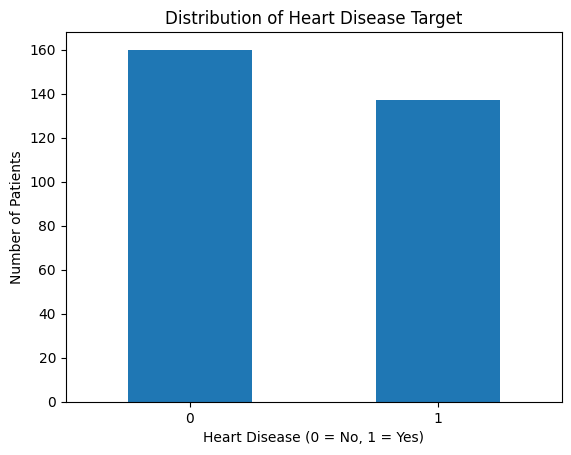

In [20]:
y_clean.value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Heart Disease Target")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

In [21]:
print(y_clean.value_counts().sort_index())

print(
    (y_clean.value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

num
0    160
1    137
Name: count, dtype: int64
num
0    53.87
1    46.13
Name: proportion, dtype: float64


### Observation:
The target distribution shows the number of patients in each heart disease class after data cleaning. Both classes are represented in the dataset, although they are not exactly equal in size. The difference is not extreme, but the class distribution was considered when splitting the data. Stratified sampling was later used during the train-test split to maintain a similar class distribution in both the training and testing sets.

## 5.2 Understand the numerical features

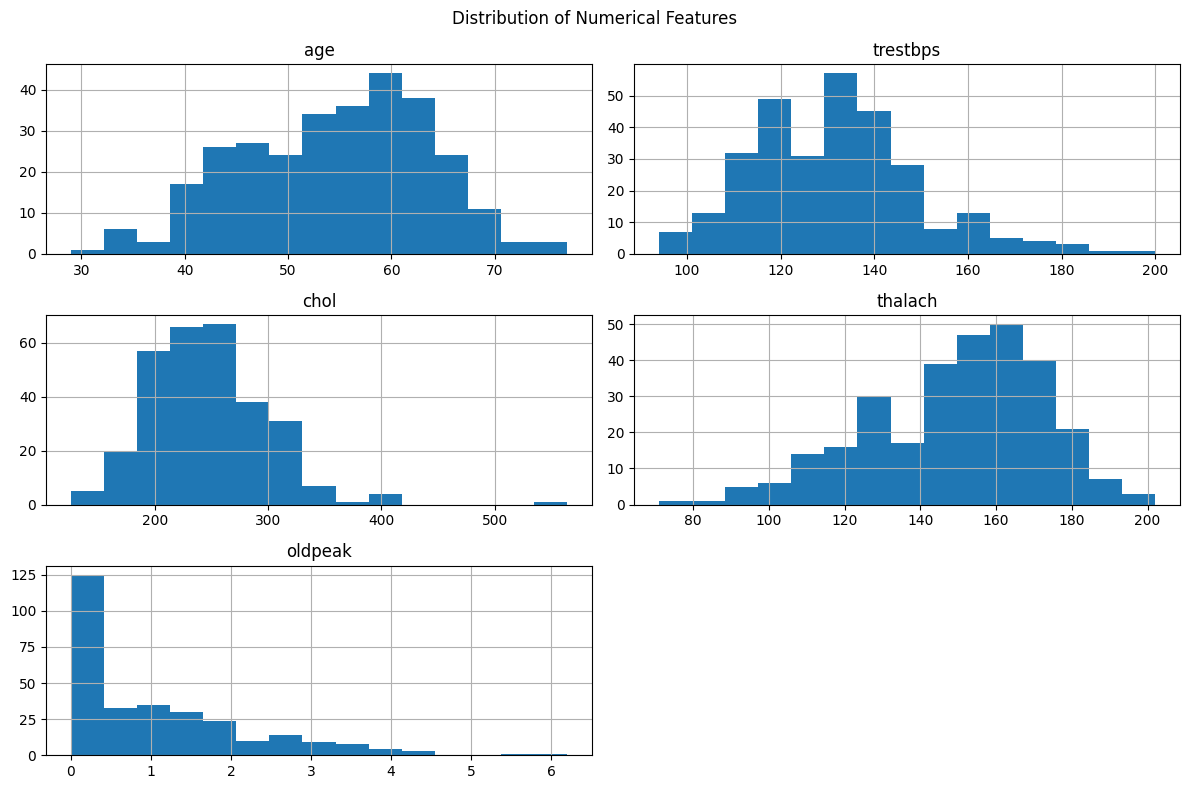

In [22]:
X_clean[["age", "trestbps", "chol", "thalach", "oldpeak"]].hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [23]:
features = ["age", "trestbps", "chol", "thalach", "oldpeak"]

print(X_clean[features].describe().round(2))
print(X_clean[features].skew().round(2))

          age  trestbps    chol  thalach  oldpeak
count  297.00    297.00  297.00   297.00   297.00
mean    54.54    131.69  247.35   149.60     1.06
std      9.05     17.76   52.00    22.94     1.17
min     29.00     94.00  126.00    71.00     0.00
25%     48.00    120.00  211.00   133.00     0.00
50%     56.00    130.00  243.00   153.00     0.80
75%     61.00    140.00  276.00   166.00     1.60
max     77.00    200.00  564.00   202.00     6.20
age        -0.22
trestbps    0.70
chol        1.12
thalach    -0.54
oldpeak     1.25
dtype: float64


## Observation:
The histograms show that the numerical features have different distributions and ranges. Age, resting blood pressure, cholesterol, and maximum heart rate show variation across the patients, while oldpeak has a more concentrated distribution with some higher values. The different ranges of these numerical features are important when preparing the data for machine learning. In particular, feature scaling is appropriate for Logistic Regression because the model can be affected by differences in feature scale.

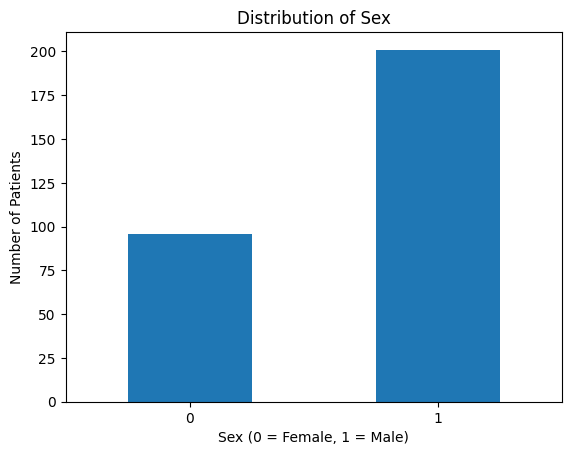

In [22]:
X_clean["sex"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Sex")
plt.xlabel("Sex (0 = Female, 1 = Male)")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

## Observation:
The bar chart shows the distribution of patients according to sex. The dataset contains both female (0) and male (1) patients, although the number of patients in the two groups is not equal. This shows that the dataset has an uneven distribution between the two categories, which is important to consider when interpreting patterns in the data.

## 5.3. Examine the chest pain(cp)

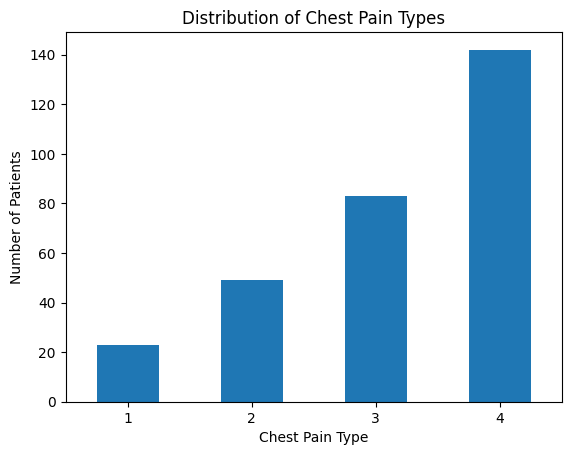

In [23]:
X_clean["cp"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Chest Pain Types")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

## Observation:
 The bar chart shows the distribution of patients across the different chest pain categories. The number of patients varies across the categories, indicating that some chest pain types are more common than others in the dataset. This distribution is useful for understanding the composition of the dataset before building the classification models.

## 5.4 Other Categorical Features together

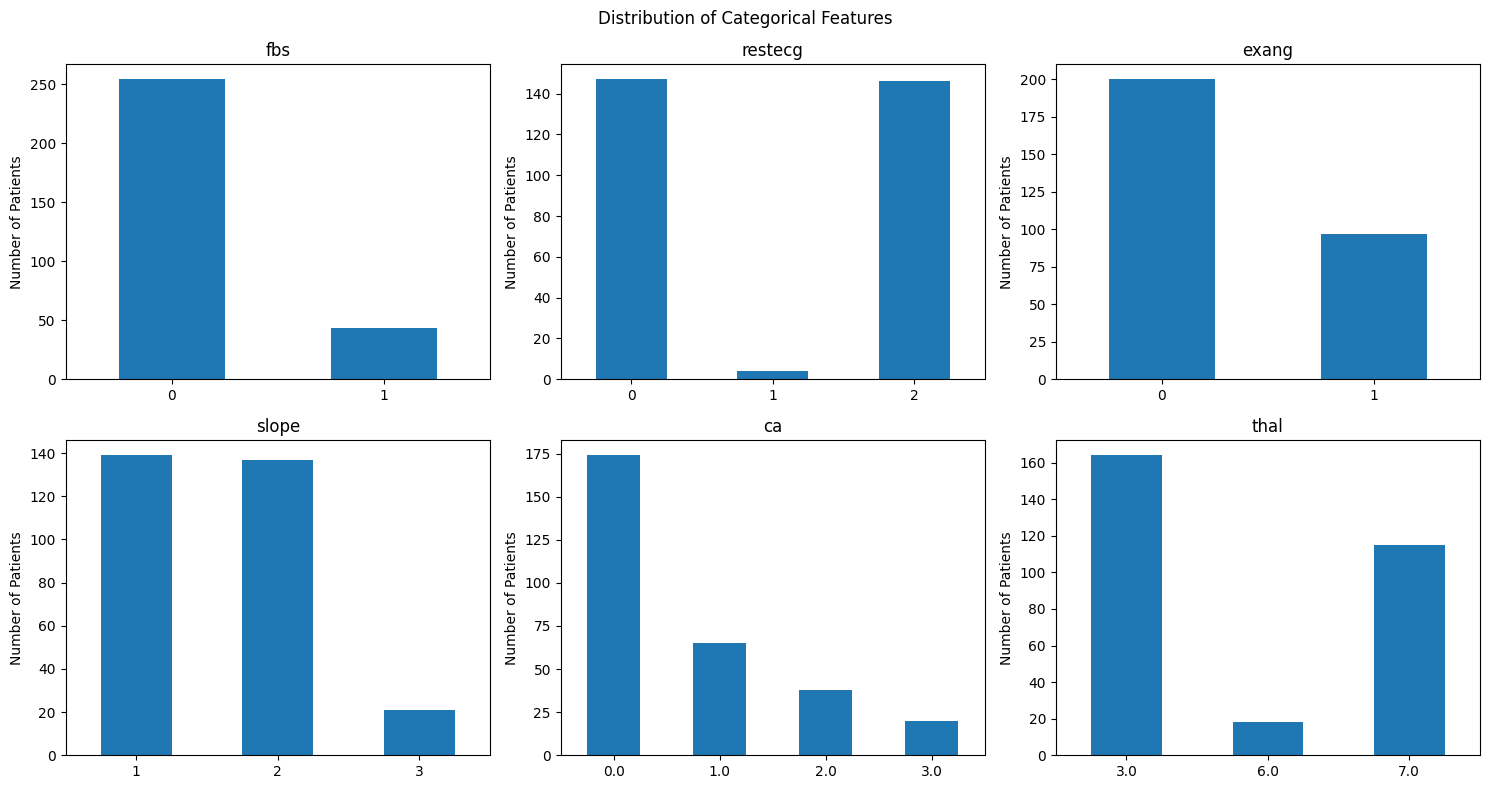

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

columns = ["fbs", "restecg", "exang", "slope", "ca", "thal"]

for ax, column in zip(axes.flat, columns):
    X_clean[column].value_counts().sort_index().plot(
        kind="bar",
        ax=ax
    )
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Number of Patients")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Distribution of Categorical Features")
plt.tight_layout()
plt.show()

## Observation:
The categorical features show different distributions across their respective categories. Some categories contain considerably more observations than others. These distributions provide an overview of the composition of the dataset and help identify categories that may have relatively few observations.

## 5.5 Correlation heatmap

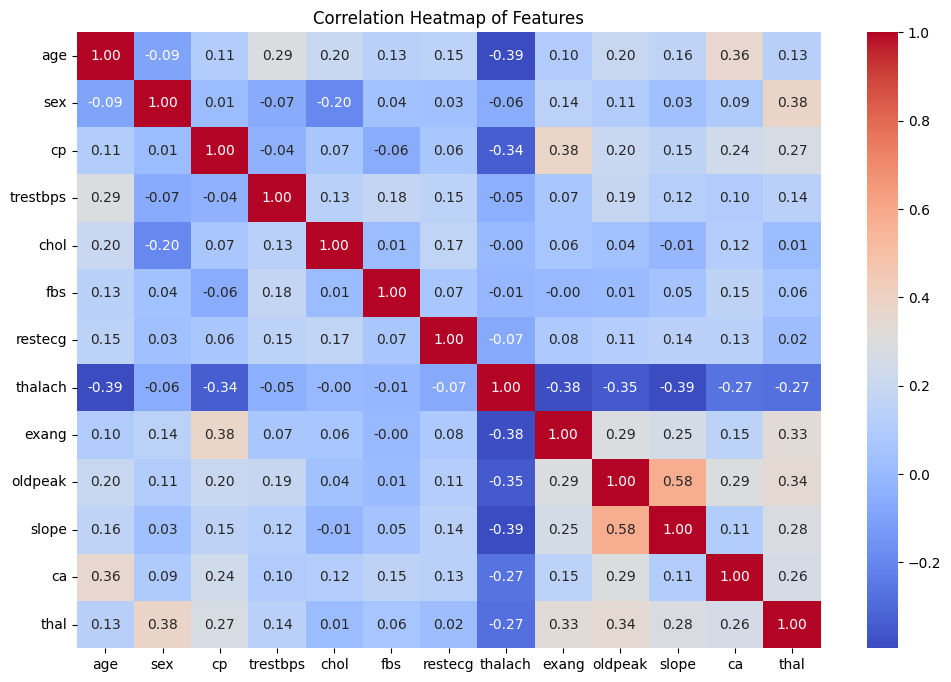

In [25]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    X_clean.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Features")
plt.show()

In [24]:
corr = X_clean.corr(numeric_only=True)

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

print(
    upper.stack()
    .sort_values(key=abs, ascending=False)
    .head(10)
    .round(3)
)

oldpeak  slope      0.579
age      thalach   -0.395
thalach  slope     -0.389
         exang     -0.384
sex      thal       0.384
cp       exang      0.378
age      ca         0.362
thalach  oldpeak   -0.348
oldpeak  thal       0.345
cp       thalach   -0.339
dtype: float64


## Observation:
The correlation heatmap shows the strength and direction of the relationships between the features. Most features do not have extremely strong correlations with each other, although some pairs show moderate relationships. The heatmap provides an overview of feature relationships and can help identify features that may contain similar information.

## 6. Preprocessing.

### 6.1. 80% for training and 20% for testing.

In [25]:
# Split the cleaned data into training and testing sets while preserving the class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean
)

## Why 80/20?
The dataset is relatively small 297 observations after cleaning so we want to retain most of the available data for training while keeping a separate test set for evaluation.

#Why stratify=y_clean?
Our target contains two classes:
- 0 → no heart disease
- 1 → heart disease

## Why We Don't Apply Scaling Before the Split

Because fit_transform() calculates information such as the mean and standard deviation from the data.
If we calculate those values using the entire dataset, information from the test set can indirectly influence the training process.

check

In [26]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (237, 13)
Testing features: (60, 13)
Training target: (237,)
Testing target: (60,)


## 6.2. Scale the features
AI Generated

In [27]:
# Standardize the features using parameters learned from the training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## What does StandardScaler do?
It transforms each feature approximately so that it has:
- mean ≈ 0
- standard deviation ≈ 1
### The basic formula is:



where:
- x = original value
- μ = mean calculated from training data
- σ = standard deviation calculated from training data

## Why We Use Scaling for Logistic Regression

Logistic Regression is sensitive to feature scale because it learns coefficients/weights while optimizing its loss function.
Scaling puts the features on a more comparable numerical scale and can make the optimization more stable.

In [28]:
print("Original shape:", X_train.shape)
print("Scaled shape:", X_train_scaled.shape)

Original shape: (237, 13)
Scaled shape: (237, 13)


The cleaned dataset was divided into training and testing sets using an 80/20 split with stratification to preserve the target-class distribution. StandardScaler was applied to the training features and then used to transform the test features for Logistic Regression because this model can be affected by differences in feature scale. Random Forest was trained using the unscaled features because tree-based models do not require feature standardization. Additional feature engineering and one-hot encoding were considered but were not applied in this baseline pipeline in order to maintain a simple and consistent representation of the original dataset. Data leakage was avoided by fitting the scaler only on the training data.

## 7 Model 1: Logistic Regression

### What is Logistic Regression?
Logistic Regression is a classification algorithm used when the outcome we want to predict belongs to categories.

Logistic Regression doesn't simply memorize the training data. It learns a relationship between the patient's features and the probability of belonging to class 0 or class 1.

## Why did we choose Logistic Regression?
We selected Logistic Regression as our first model because it is designed for classification and provides a simple, interpretable baseline.
Our dataset is relatively small, with 297 observations after cleaning, so starting with a straightforward classification algorithm gives us a useful baseline before introducing a more complex model.
## Why not use only Logistic Regression?
Because one model doesn't tell us whether a different modelling approach could capture patterns that the baseline misses.

## 7.1. Create Model

In [29]:
model_lr = LogisticRegression(random_state=42)

At this point, we have created the model, but it has not learned anything yet.

## 7.2. Train the model

In [30]:
model_lr.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

Here are the training examples and their correct answers. Learn the relationship between them.

## 7.3. Make Prediction

In [32]:
y_pred_lr = model_lr.predict(X_test_scaled)
print(y_pred_lr)

[0 0 0 0 1 0 1 0 0 0 1 0 1 1 1 0 1 0 1 1 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 0 0
 1 0 1 0 1 1 1 0 0 1 0 1 1 0 1 0 0 0 1 1 0 0 1]


A hyperparameter is a setting we choose before training rather than something the model learns directly from the training data.

## 8. Evaluate Logistic Regression

## 8.1. Calculate The Matrics

In [33]:
accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr)
recall = recall_score(y_test, y_pred_lr)
f1 = f1_score(y_test, y_pred_lr)
f2_lr = fbeta_score(y_test, y_pred_lr, beta=2)

y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("F2-score:", round(f2_lr, 4))
print("ROC-AUC:", round(roc_auc_lr, 4))

Accuracy: 0.8333333333333334
Precision: 0.8461538461538461
Recall: 0.7857142857142857
F1 Score: 0.8148148148148148
F2-score: 0.7971
ROC-AUC: 0.9498


## 8.2 Comfusion Matrix

In [34]:
cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

[[28  4]
 [ 6 22]]


## Logistic Regression Confusion Matrix
### Therefore:
- True Negatives (TN) = 28
- False Positives (FP) = 4
- False Negatives (FN) = 6
- True Positives (TP) = 22

### Interpretation
The Logistic Regression model correctly classified 28 observations as class 0 and 22 observations as class 1. It incorrectly classified 4 class-0 observations as class 1, resulting in false positives. It also classified 6 class-1 observations as class 0, resulting in false negatives.
The model therefore made 10 incorrect predictions out of 60 test observations, while correctly classifying 50 observations. This corresponds to the reported accuracy of approximately 83.33%.
The 6 false negatives are particularly important because they represent positive cases that the model failed to identify. This contributes to the model's recall of 78.57%. Therefore, although the model achieved reasonably strong overall performance, it still missed some positive cases.

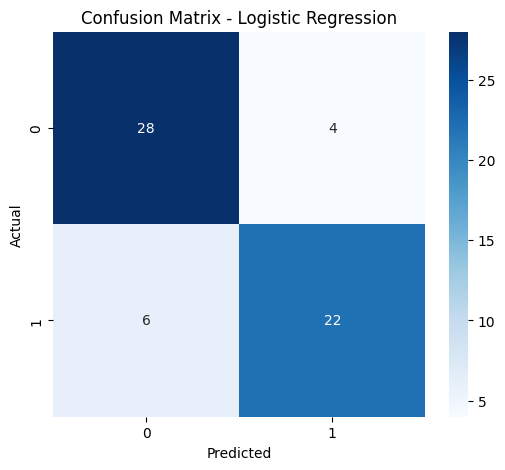

In [35]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 9. Random Forest

### Random Forest
 gives us a different modelling approach.
Instead of learning one set of coefficients like Logistic Regression, Random Forest builds many decision trees and combines their predictions.

## Why Random Forest was used
Random Forest was selected as the second model because it can capture nonlinear relationships and interactions between features that a linear model such as Logistic Regression may not capture effectively. It also does not require feature scaling, making it useful for comparing a tree-based approach with Logistic Regression.

## 9.1 create the model

In [36]:
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

n_estimators=100 means: Build 100 decision trees in the forest.

## Why 100?
We're using 100 as a reasonable baseline that provides a substantial number of trees without making the initial model unnecessarily complex or computationally expensive.
We're not claiming that 100 is mathematically optimal.
To determine an optimal value, we'd need systematic hyperparameter tuning or cross-validation, which is outside this baseline experiment.

Setting the random state makes the experiment reproducible.

## 9.2 Train the Model

In [37]:
model_rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

## 9.3 Make prediction

In [38]:
y_pred_rf = model_rf.predict(X_test)
print(y_pred_rf)

[0 0 0 1 0 0 1 0 0 0 1 0 1 1 1 0 1 0 1 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0
 1 0 1 0 1 1 1 0 0 1 0 0 1 0 1 0 0 1 1 1 0 0 1]


## 9.4 Calculate the matrics

In [39]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
f2_rf = fbeta_score(y_test, y_pred_rf, beta=2)

y_prob_rf = model_rf.predict_proba(X_test)[:, 1]
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("Random Forest Precision:", precision_rf)
print("Random Forest Recall:", recall_rf)
print("Random Forest F1 Score:", f1_rf)
print("Random Forest F2-score:", round(f2_rf, 4))
print("Random Forest ROC-AUC:", round(roc_auc_rf, 4))

Random Forest Accuracy: 0.85
Random Forest Precision: 0.88
Random Forest Recall: 0.7857142857142857
Random Forest F1 Score: 0.8301886792452831
Random Forest F2-score: 0.8029
Random Forest ROC-AUC: 0.9408


## 9.5 confusion Matrix

In [40]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[29  3]
 [ 6 22]]


## Random Forest confusion Matrix
###Therefore:
- True Negatives (TN) = 29
- False Positives (FP) = 3
- False Negatives (FN) = 6
- True Positives (TP) = 22
###Interpretation
The Random Forest model correctly classified 29 observations as class 0 and 22 observations as class 1. It incorrectly classified 3 class-0 observations as class 1 and 6 class-1 observations as class 0.
The model therefore made 9 incorrect predictions out of 60 test observations and correctly classified 51 observations, giving an accuracy of 85.00%.
The model produced the same number of false negatives (6) as Logistic Regression and the same number of true positives (22). Therefore, its recall was also 78.57%.
However, Random Forest reduced the number of false positives from 4 to 3 and increased the number of true negatives from 28 to 29. This contributed to its higher accuracy and precision.

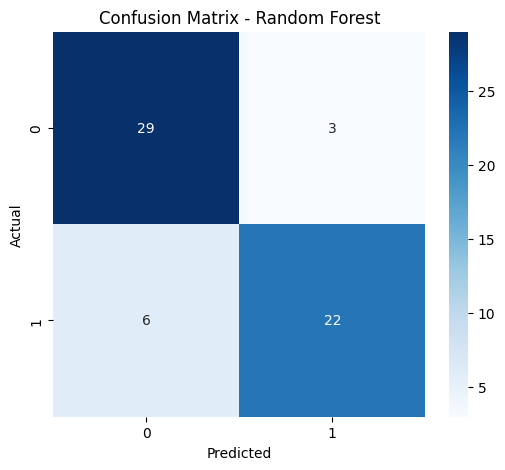

In [41]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 10. Multilayer perceptron neural netwok

## Neural network
 is a machine learning algorithm inspired by the way biological neurons process information. It consists of interconnected units called neurons, organized into layers that learn patterns from data. During training, the network adjusts its internal weights to improve its predictions.

 ### Why I used a Neural Network
I included the Neural Network to explore another machine learning approach and compare its performance with Logistic Regression and Random Forest. Unlike Logistic Regression, which models a linear decision boundary by default, a neural network can learn more complex, nonlinear relationships in the data. However, its effectiveness depends on the dataset, model configuration, and training process.

## Important note:
This Neural Network is an educational prototype for classifying heart disease presence in the dataset. Its results do not establish that it is suitable for clinical diagnosis or predicting future heart disease.

### 10.1 Create A MLPClassifier Neural Network

In this project, I used a Multilayer Perceptron (MLP), which is a type of artificial neural network, to classify observations into two categories: absence of heart disease (class 0) and presence of heart disease (class 1).

In [42]:
model_nn = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

### 10.2 Train the model

In [43]:
model_nn.fit(X_train_scaled, y_train)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(16, 8), max_iter=1000,
              random_state=42)

### 10.3. Make Prediction

In [44]:
y_pred_nn = model_nn.predict(X_test_scaled)

### 10.4 Evalute the Model

In [45]:
accuracy_score_nn = accuracy_score(y_test, y_pred_nn)
precision_score_nn = precision_score(y_test, y_pred_nn)
recall_score_nn = recall_score(y_test, y_pred_nn)
f1_score_nn = f1_score(y_test, y_pred_nn)
f2_nn = fbeta_score(y_test, y_pred_nn, beta=2)

y_prob_nn = model_nn.predict_proba(X_test_scaled)[:, 1]
roc_auc_nn = roc_auc_score(y_test, y_prob_nn)


print("Neural Network Accuracy:", accuracy_score_nn)
print("Neural Network Precision:", precision_score_nn)
print("Neural Network Recall:", recall_score_nn)
print("Neural Network F1 Score:", f1_score_nn)
print("Neural Network F2-score:", round(f2_nn, 4))
print("Neural Network ROC-AUC:", round(roc_auc_nn, 4))

Neural Network Accuracy: 0.8166666666666667
Neural Network Precision: 0.9473684210526315
Neural Network Recall: 0.6428571428571429
Neural Network F1 Score: 0.7659574468085106
Neural Network F2-score: 0.687
Neural Network ROC-AUC: 0.8951


I evaluated the Neural Network using accuracy, precision, recall, F1-score, and a confusion matrix. The model achieved an accuracy of 81.67%, precision of 94.74%, recall of 64.29%, and an F1-score of 76.60% on the test set.

These results showed that the Neural Network had the highest precision among the three models but lower recall. Its confusion matrix also showed that it missed 10 actual positive cases. This helped me understand that a high precision score does not necessarily mean a model identifies most of the positive cases correctly.

### 10.5. Neural Network Confusion Matrix

In [46]:
cm_nn = confusion_matrix(y_test, y_pred_nn)

print(cm_nn)


[[31  1]
 [10 18]]


## Neural Network Confusion Matrix

### Therefore:

- True Negatives (TN) = 31
- False Positives (FP) = 1
- False Negatives (FN) = 10
- True Positives (TP) = 18

### Interpretation

The Neural Network (MLP) model correctly classified 31 observations as class 0 (absence of heart disease) and 18 observations as class 1 (presence of heart disease). It incorrectly classified 1 class-0 observation as class 1, resulting in a false positive. It also classified 10 class-1 observations as class 0, resulting in false negatives.

The model therefore made 11 incorrect predictions out of 60 test observations while correctly classifying 49 observations. This corresponds to an accuracy of approximately 81.67%.

The 10 false negatives are particularly important because they represent positive cases that the model failed to identify. This contributes to the model's lower recall of 64.29%. Although the Neural Network achieved a high precision of 94.74%, its lower recall indicates that it missed more actual positive cases than Logistic Regression and Random Forest on this test set.

Therefore, while the Neural Network was highly accurate when predicting positive cases, its ability to identify all actual positive cases was weaker. This limitation should be considered when comparing its performance with the other models.

### 10.6 Visual Display of neural network confusion network

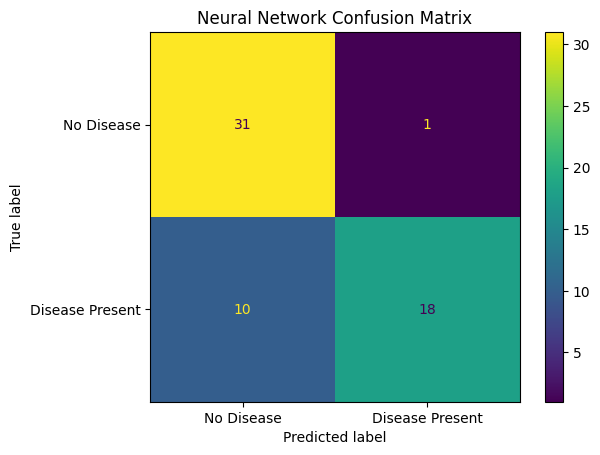

In [47]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nn,
    display_labels=["No Disease", "Disease Present"]
)

disp.plot()
plt.title("Neural Network Confusion Matrix")
plt.show()

Working with the Neural Network improved my practical knowledge of machine learning by helping me understand how to train and evaluate an MLP classifier, the importance of feature scaling, and the role of model parameters in training. Comparing its results with those of Logistic Regression and Random Forest also helped me understand that a more complex algorithm does not automatically perform better than simpler models.

## 11. Model Comparision

### 11.1 Put all model into one comparision table

In [48]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Neural Network (MLP)"
    ],
    "Accuracy": [
        accuracy, accuracy_rf, accuracy_score_nn
    ],
    "Precision": [
        precision, precision_rf, precision_score_nn
    ],
    "Recall": [
        recall, recall_rf, recall_score_nn
    ],
    "F1-score": [
        f1, f1_rf, f1_score_nn
    ],
    "F2-score": [
        f2_lr, f2_rf, f2_nn
    ],
    "ROC-AUC": [
        roc_auc_lr, roc_auc_rf, roc_auc_nn
    ]
})

results = results.set_index("Model")
results.round(4)

,Accuracy,Precision,Recall,F1-score,F2-score,ROC-AUC
Model,,,,,,
Logistic Regression,0.8333,0.8462,0.7857,0.8148,0.7971,0.9498
Random Forest,0.8500,0.8800,0.7857,0.8302,0.8029,0.9408
Neural Network (MLP),0.8167,0.9474,0.6429,0.7660,0.6870,0.8951


## Interpretation of Model Evaluation Results

### 1. Accuracy
- **Logistic Regression:** 83.33%
- **Random Forest:** 85.00%
- **Neural Network (MLP):** 81.67%

Random Forest achieved the highest accuracy, correctly classifying 51 out of 60 test observations. Logistic Regression correctly classified 50, while the Neural Network correctly classified 49. Although Random Forest performed best on this metric, the differences between the models were relatively small. These results are based on a single test split.

### 2. Precision
- **Logistic Regression:** 84.62%
- **Random Forest:** 88.00%
- **Neural Network (MLP):** 94.74%

The Neural Network achieved the highest precision. Approximately 94.74% of the observations it predicted as positive were actually positive in the test set. Random Forest ranked second, followed by Logistic Regression. However, high precision does not necessarily mean a model identifies most of the actual positive cases.

### 3. Recall
- **Logistic Regression:** 78.57%
- **Random Forest:** 78.57%
- **Neural Network (MLP):** 64.29%

Logistic Regression and Random Forest achieved the same recall. Each identified 22 of the 28 actual positive cases, missing 6. The Neural Network identified 18 of the 28 positive cases and missed 10. Its lower recall indicates that it failed to identify a larger proportion of actual positive cases than the other two models. This is an important consideration in a health-related classification task.

### 4. F1-score
- **Logistic Regression:** 81.48%
- **Random Forest:** 83.02%
- **Neural Network (MLP):** 76.60%

Random Forest achieved the highest F1-score, indicating the strongest balance between precision and recall among the three models on this test split. Logistic Regression ranked second, while the Neural Network recorded the lowest score.

### 5. F2-score
- **Logistic Regression:** 79.71%
- **Random Forest:** 80.29%
- **Neural Network (MLP):** 68.70%

Random Forest achieved the highest F2-score. Because F2-score gives more weight to recall than precision, it is useful when missed positive cases are a particular concern. Random Forest performed slightly better than Logistic Regression, while the Neural Network recorded a considerably lower score.

### 6. ROC-AUC
- **Logistic Regression:** 0.9498
- **Random Forest:** 0.9408
- **Neural Network (MLP):** 0.8951

Logistic Regression achieved the highest ROC-AUC, followed by Random Forest and the Neural Network. ROC-AUC measures how well a model distinguishes between the two classes across different classification thresholds. The results suggest that Logistic Regression had the strongest class-separation ability among the three models on this test set.

These values should be confirmed using predicted probabilities for all three models, particularly the Random Forest ROC-AUC value.

### 7. Overall Comparison

| Evaluation metric | Best-performing model |
|---|---|
| Accuracy | Random Forest |
| Precision | Neural Network (MLP) |
| Recall | Logistic Regression and Random Forest (tie) |
| F1-score | Random Forest |
| F2-score | Random Forest |
| ROC-AUC | Logistic Regression |

### Main Finding

Based on the evaluation results, Random Forest performed best in accuracy, F1-score, and F2-score, while Logistic Regression achieved the highest ROC-AUC. The Neural Network recorded the highest precision but had lower recall, meaning that its positive predictions were more often correct, although it missed more actual positive cases.

Overall, Random Forest appears to be a promising candidate for further evaluation because it achieved the highest accuracy and F2-score while maintaining the same recall as Logistic Regression. However, these findings are based on a single test split and do not establish that the model is suitable for clinical use. Further evaluation using cross-validation, additional data, and appropriate testing would be needed before drawing stronger conclusions.

## Evaluation Summary:
Logistic Regression and Random Forest were evaluated using accuracy, precision, recall, F1-score, and confusion matrices. Random Forest achieved the highest accuracy (85.00%), precision (88.00%), and F1-score (83.02%), while both models achieved the same recall of 78.57%. Based on these results, Random Forest performed better overall on the selected test set. However, the results should be interpreted cautiously because the dataset is relatively small, the evaluation uses a single train-test split, and no extensive hyperparameter tuning or external validation was performed. The models should therefore be considered baseline research models rather than clinically validated diagnostic systems.

### Inspect which features contributed most in the prediction

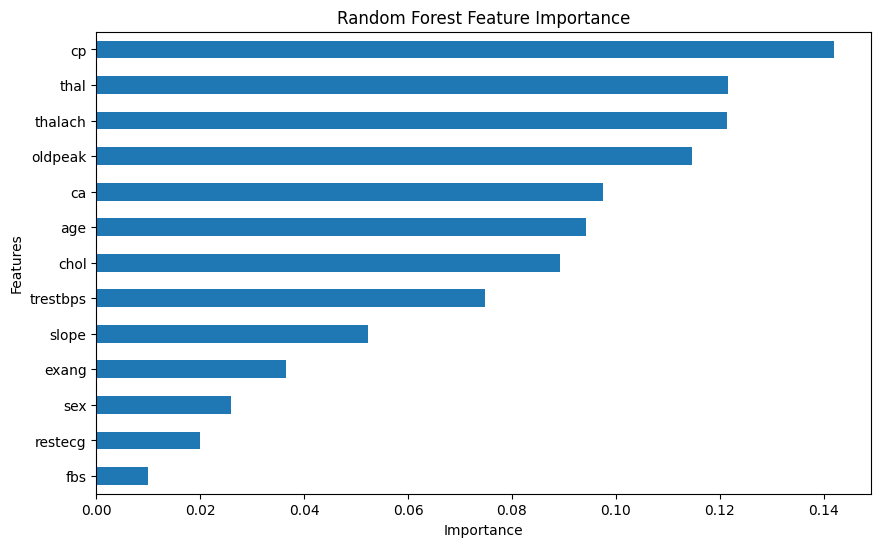

In [49]:
feature_importance = pd.Series(
    model_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

feature_importance.plot(kind="barh", figsize=(10, 6))

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

# 11 Challenges Encountered

### 1 Missing values

The original dataset contained missing values in ca and thal. We had to investigate them before deciding how to handle them.
### Lesson:
Cleaning isn't simply about removing whatever causes an error. Each cleaning decision needs a reason.

### 2 Understanding the machine-learning workflow

I initially had to understand the difference between:

fit()

predict()


I learned that

### model.fit(X_train, y_train)

means the model learns from training data, while:

### model.predict(X_test)
uses what it learned to make predictions on unseen data.

### Lesson:
A machine-learning model isn't just a piece of code that produces an answer; it has a training stage and a prediction stage.


## 3 Choosing preprocessing based on the model

We didn't blindly scale everything.
We used:

Logistic Regression: I used StandardScaler to standardize the features because differences in feature scales can affect how the model learns.



Random Forest: I used the original features because tree-based models generally do not require feature scaling.



Neural Network (MLP): I used StandardScaler because neural networks generally train more effectively when input features have comparable scales.

### Lesson:
Preprocessing should depend on the characteristics of the algorithm rather than applying transformations simply because they are available.

## 4 Understanding Model Evaluation Metrics

Another challenge I encountered was understanding why accuracy alone is insufficient for evaluating a classification model. Initially, I focused mainly on the number of observations each model classified correctly. However, comparing Logistic Regression, Random Forest, and Neural Network (MLP) helped me understand the importance of evaluating models using multiple performance metrics.

Logistic Regression and Random Forest both achieved a recall of 78.57%, although Random Forest recorded higher accuracy and precision. In contrast, the Neural Network achieved the highest precision of 94.74% but a lower recall of 64.29%. This demonstrated that a model can perform well in one area while having limitations in another.

To better understand these differences, I evaluated precision, recall, F1-score, F2-score, ROC-AUC, and confusion matrices. This experience strengthened my understanding of model evaluation and taught me that selecting a suitable model requires considering multiple performance metrics rather than relying on accuracy alone.

# 11.2 What I Learned

This project helped me understand the complete machine learning workflow rather than treating individual code blocks as separate tasks. I learned how to inspect and clean a dataset, explore patterns through visualisation, prepare data for different algorithms, train classification models, and evaluate their predictions using several metrics. I also learned that a higher accuracy does not automatically mean that a model is better for every situation.

# 11.3 What I Would Do Differently

If I were to continue the project, I would test the models using cross-validation and perform systematic hyperparameter tuning rather than relying on a single train-test split. I would also investigate alternative approaches to encoding the categorical variables and evaluate whether they improve the models. A larger and more representative dataset would also be needed before considering the system for any real-world application.

In [51]:

import joblib

joblib.dump(
    model_rf,
    "heart_disease_model.pkl"
)


['heart_disease_model.pkl']